In [75]:
import pandas as pd
import numpy as np
import joblib
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import seaborn as sns
import matplotlib.pyplot as plt


In [76]:
pd.set_option('display.max_columns', None) ## despliega todas las columnas

In [77]:
df=pd.read_csv("../data/raw/smoking_prediction_sin_etiquetar.csv")
df.head(4)


,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar
0,27358,M,25,160,65,3.42,0.05,0.00,0.04,0.04,5.04,3.13,4.00,5.46,2.29,1.96,3.04,0.63,0.04,0.01,0.75,0.71,0.71,Y,0,Y
1,27364,M,30,180,80,3.46,0.04,0.01,0.04,0.04,5.38,3.25,4.17,7.92,10.96,1.50,4.21,0.59,0.04,0.04,0.79,1.13,1.33,Y,0,N
2,27368,M,55,165,60,3.42,0.00,0.01,0.04,0.04,5.25,3.46,4.08,6.96,13.92,2.13,2.04,0.63,0.04,0.01,1.08,1.29,2.00,Y,1,Y
3,27378,M,20,175,75,3.63,0.05,0.05,0.04,0.04,5.33,3.50,3.75,6.50,5.29,1.71,3.71,0.63,0.04,0.04,0.83,0.58,0.46,Y,0,N


In [78]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5692 entries, 0 to 5691
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   5692 non-null   int64  
 1   gender               5692 non-null   str    
 2   age                  5692 non-null   int64  
 3   height(cm)           5692 non-null   int64  
 4   weight(kg)           5692 non-null   int64  
 5   waist(cm)            5692 non-null   float64
 6   eyesight(left)       5692 non-null   float64
 7   eyesight(right)      5692 non-null   float64
 8   hearing(left)        5692 non-null   float64
 9   hearing(right)       5692 non-null   float64
 10  systolic             5692 non-null   float64
 11  relaxation           5692 non-null   float64
 12  fasting blood sugar  5692 non-null   float64
 13  Cholesterol          5692 non-null   float64
 14  triglyceride         5692 non-null   float64
 15  HDL                  5692 non-null   float64
 16 

In [79]:
df.shape

(5692, 26)

In [80]:
df.duplicated().value_counts()

False    5692
Name: count, dtype: int64

# Transformaciones

In [81]:
df=df.drop(columns=['ID','oral'])

In [82]:
df.shape

(5692, 24)

In [83]:
df.duplicated().value_counts() ## filas duplicadas luego de sacar ID, oral --> de

False    5692
Name: count, dtype: int64

In [84]:
df['gender']=(df['gender'] == "M").astype(int)  ## F=0, M=1
df['tartar']=(df['tartar'] == "Y").astype(int)  ## N=0, Y=1

In [85]:
## las variables 'hearing(left)', 'hearing(right)', toma valores 0.04 y 0.08 --> convierto a binarias
df['hearing(left)']=(df['hearing(left)'] > 0.04).astype(int)  ## 0.04=0, 0.08=1
df['hearing(right)']=(df['hearing(right)'] > 0.04).astype(int)  ## 0.04=0, 0.08=1

In [86]:
df.head(4)

,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,tartar
0,1,25,160,65,3.42,0.05,0.00,0,0,5.04,3.13,4.00,5.46,2.29,1.96,3.04,0.63,0.04,0.01,0.75,0.71,0.71,0,1
1,1,30,180,80,3.46,0.04,0.01,0,0,5.38,3.25,4.17,7.92,10.96,1.50,4.21,0.59,0.04,0.04,0.79,1.13,1.33,0,0
2,1,55,165,60,3.42,0.00,0.01,0,0,5.25,3.46,4.08,6.96,13.92,2.13,2.04,0.63,0.04,0.01,1.08,1.29,2.00,1,1
3,1,20,175,75,3.63,0.05,0.05,0,0,5.33,3.50,3.75,6.50,5.29,1.71,3.71,0.63,0.04,0.04,0.83,0.58,0.46,0,0


In [87]:
df.columns

Index(['gender', 'age', 'height(cm)', 'weight(kg)', 'waist(cm)',
       'eyesight(left)', 'eyesight(right)', 'hearing(left)', 'hearing(right)',
       'systolic', 'relaxation', 'fasting blood sugar', 'Cholesterol',
       'triglyceride', 'HDL', 'LDL', 'hemoglobin', 'Urine protein',
       'serum creatinine', 'AST', 'ALT', 'Gtp', 'dental caries', 'tartar'],
      dtype='str')

# Cargo las features entrenadas

In [88]:
features=joblib.load("../models/features_XGB_optimizado.joblib")
features

['gender',
 'age',
 'height(cm)',
 'weight(kg)',
 'waist(cm)',
 'eyesight(left)',
 'eyesight(right)',
 'hearing(left)',
 'hearing(right)',
 'systolic',
 'relaxation',
 'fasting blood sugar',
 'Cholesterol',
 'triglyceride',
 'HDL',
 'LDL',
 'hemoglobin',
 'Urine protein',
 'serum creatinine',
 'AST',
 'ALT',
 'Gtp',
 'dental caries',
 'tartar']

In [89]:
X=df[features]
X

,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,tartar
0,1,25,160,65,3.42,0.05,0.00,0,0,5.04,3.13,4.00,5.46,2.29,1.96,3.04,0.63,0.04,0.01,0.75,0.71,0.71,0,1
1,1,30,180,80,3.46,0.04,0.01,0,0,5.38,3.25,4.17,7.92,10.96,1.50,4.21,0.59,0.04,0.04,0.79,1.13,1.33,0,0
2,1,55,165,60,3.42,0.00,0.01,0,0,5.25,3.46,4.08,6.96,13.92,2.13,2.04,0.63,0.04,0.01,1.08,1.29,2.00,1,1
3,1,20,175,75,3.63,0.05,0.05,0,0,5.33,3.50,3.75,6.50,5.29,1.71,3.71,0.63,0.04,0.04,0.83,0.58,0.46,0,0
4,1,25,165,80,3.79,0.04,0.04,0,0,4.50,3.00,4.17,10.46,7.25,2.38,6.63,0.67,0.04,0.04,1.25,1.63,1.96,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5687,0,40,170,65,3.13,0.01,0.01,0,0,4.58,2.83,3.71,8.88,4.13,3.13,4.92,0.50,0.04,0.00,0.58,0.29,0.42,1,1
5688,0,45,160,50,2.92,0.04,0.04,0,0,4.21,2.58,3.71,6.92,2.88,3.04,3.29,0.58,0.04,0.01,0.83,0.50,0.58,0,1
5689,0,55,160,50,2.84,0.04,0.04,0,0,4.88,3.00,3.67,6.58,3.21,3.29,2.63,0.50,0.04,0.00,0.71,0.46,0.50,0,0
5690,1,60,165,60,3.25,0.01,0.04,0,0,5.54,3.17,4.46,8.75,3.29,2.00,6.08,0.59,0.04,0.00,0.83,0.79,0.75,0,0


# Cargo umbral

In [90]:
umbral = joblib.load("../models/mejor_umbral.joblib")

In [91]:
umbral

np.float32(0.4055094)

# Predicciones

In [92]:
## Cargo modelo entrenado
## Aplico umbral sobre las predicciones
## Genero prediciones sobre df

In [93]:
clf=joblib.load("../models/mod_XGB_optimizado.joblib")
clf

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,0.5
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [94]:
proba_predict = clf.predict_proba(X)[:,1]

In [95]:
proba_predict

array([0.395348  , 0.5076161 , 0.78675556, ..., 0.03002538, 0.3558516 ,
       0.6036352 ], shape=(5692,), dtype=float32)

In [96]:
df["smoking_prediction"] = (proba_predict >= umbral).astype(int)

In [97]:
print("Recuentos para smoking:  ", df["smoking_prediction"].value_counts())

Recuentos para smoking:   smoking_prediction
1    3037
0    2655
Name: count, dtype: int64


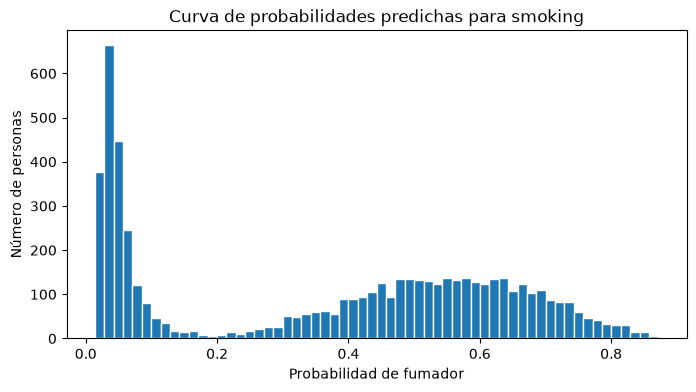

In [98]:
plt.figure(figsize=(8, 4))
plt.hist(proba_predict, bins=60, edgecolor="white")
plt.xlabel("Probabilidad de fumador")
plt.ylabel("Número de personas")
plt.title("Curva de probabilidades predichas para smoking")
plt.show()

In [99]:
df.head(4)

,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,fasting blood sugar,Cholesterol,triglyceride,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,tartar,smoking_prediction
0,1,25,160,65,3.42,0.05,0.00,0,0,5.04,3.13,4.00,5.46,2.29,1.96,3.04,0.63,0.04,0.01,0.75,0.71,0.71,0,1,0
1,1,30,180,80,3.46,0.04,0.01,0,0,5.38,3.25,4.17,7.92,10.96,1.50,4.21,0.59,0.04,0.04,0.79,1.13,1.33,0,0,1
2,1,55,165,60,3.42,0.00,0.01,0,0,5.25,3.46,4.08,6.96,13.92,2.13,2.04,0.63,0.04,0.01,1.08,1.29,2.00,1,1,1
3,1,20,175,75,3.63,0.05,0.05,0,0,5.33,3.50,3.75,6.50,5.29,1.71,3.71,0.63,0.04,0.04,0.83,0.58,0.46,0,0,0


## Guardado de predicciones

In [100]:
df.to_csv("../data/processed/smoking_predicciones.csv")